In [1]:
import pickle
import polars as pl
import pandas as pd
import numpy as np
from sklearn.metrics import root_mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def load_real_data(path):
    exp_data = pl.read_excel(path, engine="calamine")
    exp_compositions = exp_data.select([ 'FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H'])
    exp_compositions_np = exp_compositions.to_numpy()
    
    return exp_compositions_np

def load_predicted_data(path):
    
    calculated_data = pl.read_excel(path, engine="calamine")
    calculated_data_np = calculated_data.to_numpy()
    return calculated_data_np

def calculate_RMSE(exp_compositions_np, calculated_data_np):
    results = np.sqrt(np.mean((exp_compositions_np - calculated_data_np)**2, 0)).reshape(1, 16)
    results = pl.DataFrame(results, schema=['FAME/FAEE_L', 'GLYCEROL_L', 'ALCOHOL_L', 'OIL_L', 'DAG_L', 'MAG_L', 'ACID_L', 'WATER_L', 
                                            'FAME/FAEE_H', 'GLYCEROL_H', 'ALCOHOL_H', 'OIL_H', 'DAG_H', 'MAG_H', 'ACID_H', 'WATER_H']) 

    return results

# Compute the mean of paired columns (0 with 8, 1 with 9, ..., 7 with 15)
def component_mean(df):
    columns = [
    "FAME/FAEE_L", "GLYCEROL_L", "ALCOHOL_L", "OIL_L", 
    "DAG_L", "MAG_L", "ACID_L", "WATER_L",
    "FAME/FAEE_H", "GLYCEROL_H", "ALCOHOL_H", "OIL_H", 
    "DAG_H", "MAG_H", "ACID_H", "WATER_H"
    ]


# Compute mean for each (_L, _H) pair
    means = df.select([
    ((pl.col(low) + pl.col(high)) / 2).alias(f"mean_{low}_{high}")
    for low, high in zip(columns[:8], columns[8:])
    ]) 
    return means

### UNIFAC

In [34]:
exp_compositions_np = load_real_data(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
calculated_data_np = load_predicted_data(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\Others\results_predict_total_UNIFAC_fixed_predict_1.xlsx")

In [35]:
unifac_results = calculate_RMSE(exp_compositions_np, calculated_data_np)
means = component_mean(unifac_results)
means

mean_FAME/FAEE_L_FAME/FAEE_H,mean_GLYCEROL_L_GLYCEROL_H,mean_ALCOHOL_L_ALCOHOL_H,mean_OIL_L_OIL_H,mean_DAG_L_DAG_H,mean_MAG_L_MAG_H,mean_ACID_L_ACID_H,mean_WATER_L_WATER_H
f64,f64,f64,f64,f64,f64,f64,f64
0.198858,0.175625,0.222387,0.13087,0.002372,0.004294,0.028596,0.100477


#### UNIFAC Correlated

In [3]:
exp_compositions_np = load_real_data(r"C:\Juan\maestria\ThermOleo\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
exp_compositions_np_train = load_real_data(r"C:\Juan\maestria\ThermOleo\Evaluation\Stochastic_optimization\GA\unifac_train_data.xlsx")
exp_compositions_np_test = load_real_data(r"C:\Juan\maestria\ThermOleo\Evaluation\Stochastic_optimization\GA\unifac_test_data.xlsx")
calculated_data_np_total = load_predicted_data(r"C:\Juan\maestria\ThermOleo\Evaluation\Stochastic_optimization\GA\unifac_total_results.xlsx")
calculated_data_np_train = load_predicted_data(r"C:\Juan\maestria\ThermOleo\Evaluation\Stochastic_optimization\GA\unifac_train_results.xlsx")
calculated_data_np_test = load_predicted_data(r"C:\Juan\maestria\ThermOleo\Evaluation\Stochastic_optimization\GA\unifac_test_results.xlsx")

In [4]:
unifac_results = calculate_RMSE(exp_compositions_np, calculated_data_np_total)
means = component_mean(unifac_results)
means

mean_FAME/FAEE_L_FAME/FAEE_H,mean_GLYCEROL_L_GLYCEROL_H,mean_ALCOHOL_L_ALCOHOL_H,mean_OIL_L_OIL_H,mean_DAG_L_DAG_H,mean_MAG_L_MAG_H,mean_ACID_L_ACID_H,mean_WATER_L_WATER_H
f64,f64,f64,f64,f64,f64,f64,f64
0.081209,0.077511,0.143917,0.072753,0.002802,0.006271,0.039521,0.051223


In [5]:
unifac_results = calculate_RMSE(exp_compositions_np_train, calculated_data_np_train)
means = component_mean(unifac_results)
means

mean_FAME/FAEE_L_FAME/FAEE_H,mean_GLYCEROL_L_GLYCEROL_H,mean_ALCOHOL_L_ALCOHOL_H,mean_OIL_L_OIL_H,mean_DAG_L_DAG_H,mean_MAG_L_MAG_H,mean_ACID_L_ACID_H,mean_WATER_L_WATER_H
f64,f64,f64,f64,f64,f64,f64,f64
0.079178,0.071719,0.139421,0.070497,0.00313,0.007014,0.039818,0.050429


In [6]:
unifac_results = calculate_RMSE(exp_compositions_np_test, calculated_data_np_test)
means = component_mean(unifac_results)
means

mean_FAME/FAEE_L_FAME/FAEE_H,mean_GLYCEROL_L_GLYCEROL_H,mean_ALCOHOL_L_ALCOHOL_H,mean_OIL_L_OIL_H,mean_DAG_L_DAG_H,mean_MAG_L_MAG_H,mean_ACID_L_ACID_H,mean_WATER_L_WATER_H
f64,f64,f64,f64,f64,f64,f64,f64
0.077545,0.083647,0.135871,0.057199,0.0003,0.0,0.03901,0.047179


#### Unifac Dortmund

In [36]:
exp_compositions_np = load_real_data(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
calculated_data_np = load_predicted_data(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\results_predict_total_GA_Run1.xlsx")

In [ ]:
unifacD_results = calculate_RMSE(exp_compositions_np, calculated_data_np)
means = component_mean(unifacD_results)
means

mean_FAME/FAEE_L_FAME/FAEE_H,mean_GLYCEROL_L_GLYCEROL_H,mean_ALCOHOL_L_ALCOHOL_H,mean_OIL_L_OIL_H,mean_DAG_L_DAG_H,mean_MAG_L_MAG_H,mean_ACID_L_ACID_H,mean_WATER_L_WATER_H
f64,f64,f64,f64,f64,f64,f64,f64
0.082501,0.077965,0.152846,0.090655,0.00383,0.007908,0.010876,0.050421


In [8]:
exp_compositions_np = load_real_data(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
calculated_data_np = load_predicted_data(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\results_predict_total_GA_no_iter.xlsx")

In [9]:
calculate_RMSE(exp_compositions_np, calculated_data_np)

FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.076722,0.015537,0.123957,0.103804,0.003894,0.007974,0.033918,0.016442,0.023334,0.106077,0.127548,0.10477,0.000982,0.001888,0.04117,0.095057


In [10]:
exp_compositions_np = load_real_data(r"C:\Juan\Maestría\Code\oleosim\ExperimentalData\data\No 47exp\refined_lle_data_v5.xlsx")
calculated_data_np = load_predicted_data(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\results_predict_total_M1GA_no_iter.xlsx")

In [11]:
calculate_RMSE(exp_compositions_np, calculated_data_np)

FAME/FAEE_L,GLYCEROL_L,ALCOHOL_L,OIL_L,DAG_L,MAG_L,ACID_L,WATER_L,FAME/FAEE_H,GLYCEROL_H,ALCOHOL_H,OIL_H,DAG_H,MAG_H,ACID_H,WATER_H
f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0.08097,0.016497,0.103635,0.087769,0.003893,0.007961,0.02709,0.09104,0.024463,0.104765,0.156071,0.099824,0.000982,0.001887,0.026705,0.113832


#### Parameters

In [13]:
params = np.loadtxt(r"C:\Juan\Maestría\Code\oleosim\Evaluation\Stochastic_optimization\GA\UDortmundParamsGARun1.out")
params_a = np.array(params[0:30])
params_b = np.array(params[30:60])
params_c = np.array(params[60:90])

In [17]:
A = params_a.reshape((6,5))
B = params_b.reshape((6,5))
C = params_c.reshape((6,5))
         
GIP = np.zeros((6, 6, 3), dtype=np.float64) 
        
GIP[:, :, 0] =  np.array([         
                                    [0,         A[0][0],  A[0][1],  A[0][2],  A[0][3],  A[0][4]],
                                    [A[1][0],        0,   A[2][0],  A[2][1],  A[2][2],  A[2][3]],
                                    [A[1][1],   A[4][0],       0,   A[2][4],  A[3][0],  A[3][1]], 
                                    [A[1][2],   A[4][1],  A[4][4],      0,    A[3][2],  A[3][3]], 
                                    [A[1][3],   A[4][2],  A[5][0],  A[5][2],      0,    A[3][4]],
                                    [A[1][4],   A[4][3],  A[5][1],  A[5][3],  A[5][4],       0  ]  
                                    ], dtype = np.float64) 
                            
            
GIP[:, :, 1] = np.array([           
                                    [0,         B[0][0], B[0][1],  B[0][2],  B[0][3],  B[0][4]],
                                    [B[1][0],      0,    B[2][0],  B[2][1],  B[2][2],  B[2][3]],
                                    [B[1][1],   B[4][0],     0,    B[2][4],  B[3][0],  B[3][1]], 
                                    [B[1][2],   B[4][1],  B[4][4],      0,   B[3][2],  B[3][3]], 
                                    [B[1][3],   B[4][2],  B[5][0], B[5][2],     0,     B[3][4]],
                                    [B[1][4],   B[4][3],  B[5][1], B[5][3],  B[5][4],      0  ]  
                                    ], dtype = np.float64)
                
        
GIP[:, :, 2] = np.array([          
                                    [0,         C[0][0],  C[0][1], C[0][2],  C[0][3],  C[0][4]],
                                    [C[1][0],      0,     C[2][0], C[2][1],  C[2][2],  C[2][3]],
                                    [C[1][1],   C[4][0],     0,    C[2][4],  C[3][0],  C[3][1]], 
                                    [C[1][2],   C[4][1],  C[4][4],     0,    C[3][2],  C[3][3]], 
                                    [C[1][3],   C[4][2],  C[5][0], C[5][2],     0,     C[3][4]],
                                    [C[1][4],   C[4][3],  C[5][1], C[5][3], C[5][4],      0   ]  
                                        ], dtype = np.float64)

In [19]:
GIP[:, :, 0]

array([[ 0.        , -0.52128242,  1.33233297, -0.80960185, -0.45529374,
         1.74643005],
       [-1.13710763,  0.        , -0.58795406, -0.44014695,  1.87275794,
         1.74953739],
       [ 1.62629307, -1.65233506,  0.        , -0.84597616, -1.89762826,
         1.41453683],
       [ 0.37206986,  1.17624372, -1.23784974,  0.        , -0.5432559 ,
        -1.27118576],
       [ 1.58280228, -0.82328491,  0.66402747,  1.86330465,  0.        ,
         0.26952532],
       [ 1.41648021,  1.42465672, -1.1461843 , -0.32114494, -1.40016613,
         0.        ]])

In [20]:
GIP[:, :, 1]


array([[ 0.        , -1.62595621,  0.53274644, -0.16031113,  1.25130071,
         1.7773432 ],
       [-0.36377721,  0.        , -0.70890076, -0.47510121, -0.29388734,
         1.71014839],
       [-1.84137912, -1.41376257,  0.        ,  0.3230462 , -0.75801276,
         0.37290847],
       [-0.017355  ,  0.09460628, -1.22991917,  0.        , -0.79101536,
         1.09940532],
       [-1.70240368,  0.43828779,  0.190194  , -1.09385244,  0.        ,
         0.62695973],
       [ 1.44349142, -0.62637103,  0.9515889 , -0.41154456, -0.30683273,
         0.        ]])

In [21]:

GIP[:, :, 2]

array([[ 0.        ,  1.45796934, -1.13718672, -1.84722077,  0.37003365,
        -0.38803571],
       [ 0.91101555,  0.        , -0.85161842, -0.74622437, -0.1946477 ,
        -0.1359282 ],
       [ 0.60469041, -1.05854884,  0.        ,  1.73960736, -0.61892398,
        -0.29960547],
       [-1.33169887, -1.44823156,  1.47159219,  0.        , -1.89695163,
        -0.39216878],
       [ 1.90678314, -0.64809137,  0.1814578 ,  0.33410092,  0.        ,
         0.89027727],
       [ 0.57990339,  1.88881789, -0.79667603, -1.31802698, -0.35228061,
         0.        ]])

In [2]:
with open('analysis_dict.pkl', 'rb') as f:
    loaded_dict = pickle.load(f)

In [3]:
rows = []
for (ref, sub, temperature), values in loaded_dict.items():
    rows.append({
        'ref': ref,
        'sub ref': sub,
        'temperature': temperature,
        'iterations': len(values),
        'last_value': values[-1]  # Last value in the list
    })

# Create Polars DataFrame
iteration_analysis = pl.DataFrame(rows)


In [4]:
iteration_analysis = iteration_analysis.with_columns(
    pl.when(
        pl.col('ref').is_between(1, 28) | (pl.col('ref') == 48)
    )
    .then(pl.lit('biodiesel system'))
    .when(
        pl.col('ref').is_between(29, 47) | (pl.col('ref') == 57)
    )
    .then(pl.lit('oil system'))
    .when(
        pl.col('ref').is_between(49, 56)
    )
    .then(pl.lit('biodiesel system'))
    .otherwise(pl.lit('unknown'))
    .alias('system_type')
)

In [5]:
with pl.Config(tbl_rows=-1):
    print(iteration_analysis)

shape: (154, 6)
┌─────┬─────────┬─────────────┬────────────┬────────────┬──────────────────┐
│ ref ┆ sub ref ┆ temperature ┆ iterations ┆ last_value ┆ system_type      │
│ --- ┆ ---     ┆ ---         ┆ ---        ┆ ---        ┆ ---              │
│ i64 ┆ str     ┆ f64         ┆ i64        ┆ f64        ┆ str              │
╞═════╪═════════╪═════════════╪════════════╪════════════╪══════════════════╡
│ 1   ┆ a       ┆ 298.15      ┆ 6          ┆ 0.007085   ┆ biodiesel system │
│ 2   ┆ a       ┆ 293.15      ┆ 7          ┆ 0.004304   ┆ biodiesel system │
│ 2   ┆ a       ┆ 313.15      ┆ 7          ┆ 0.0066     ┆ biodiesel system │
│ 2   ┆ a       ┆ 333.15      ┆ 7          ┆ 0.006184   ┆ biodiesel system │
│ 3   ┆ a       ┆ 298.15      ┆ 8          ┆ 0.002831   ┆ biodiesel system │
│ 3   ┆ a       ┆ 318.15      ┆ 8          ┆ 0.003387   ┆ biodiesel system │
│ 3   ┆ a       ┆ 338.15      ┆ 8          ┆ 0.0041     ┆ biodiesel system │
│ 4   ┆ a       ┆ 293.15      ┆ 8          ┆ 0.003267   ┆ bi

In [6]:

with pl.Config(tbl_rows=-1):
    filtered_analysis = iteration_analysis.filter(pl.col("iterations")==100)
    print(filtered_analysis)

shape: (45, 6)
┌─────┬─────────┬─────────────┬────────────┬────────────┬──────────────────┐
│ ref ┆ sub ref ┆ temperature ┆ iterations ┆ last_value ┆ system_type      │
│ --- ┆ ---     ┆ ---         ┆ ---        ┆ ---        ┆ ---              │
│ i64 ┆ str     ┆ f64         ┆ i64        ┆ f64        ┆ str              │
╞═════╪═════════╪═════════════╪════════════╪════════════╪══════════════════╡
│ 21  ┆ a       ┆ 313.0       ┆ 100        ┆ 19.586656  ┆ biodiesel system │
│ 21  ┆ a       ┆ 333.0       ┆ 100        ┆ 20.049283  ┆ biodiesel system │
│ 23  ┆ c       ┆ 298.2       ┆ 100        ┆ 0.598379   ┆ biodiesel system │
│ 27  ┆ a       ┆ 303.15      ┆ 100        ┆ 0.656195   ┆ biodiesel system │
│ 27  ┆ a       ┆ 318.15      ┆ 100        ┆ 1.399713   ┆ biodiesel system │
│ 27  ┆ a       ┆ 333.15      ┆ 100        ┆ 0.915546   ┆ biodiesel system │
│ 48  ┆ b       ┆ 298.2       ┆ 100        ┆ 0.635497   ┆ biodiesel system │
│ 29  ┆ a       ┆ 293.15      ┆ 100        ┆ 12.760963  ┆ oil

In [7]:
filtered_analysis.to_pandas()

,ref,sub ref,temperature,iterations,last_value,system_type
0,21,a,313.00,100,19.586656,biodiesel system
1,21,a,333.00,100,20.049283,biodiesel system
2,23,c,298.20,100,0.598379,biodiesel system
3,27,a,303.15,100,0.656195,biodiesel system
4,27,a,318.15,100,1.399713,biodiesel system
5,27,a,333.15,100,0.915546,biodiesel system
6,48,b,298.20,100,0.635497,biodiesel system
7,29,a,293.15,100,12.760963,oil system
8,29,a,303.15,100,15.150206,oil system
9,29,b,298.15,100,8.548991,oil system


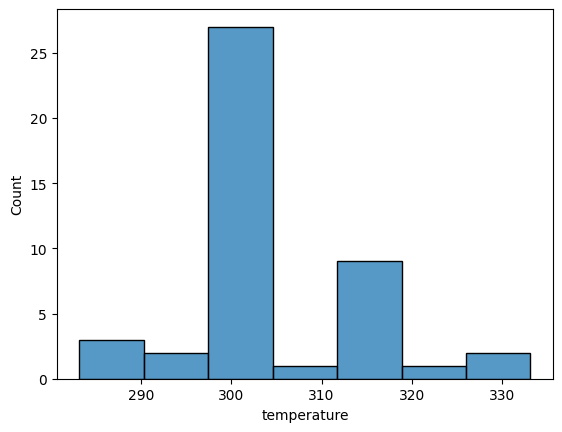

In [13]:
sns.histplot(data=filtered_analysis, x="temperature")
plt.show()

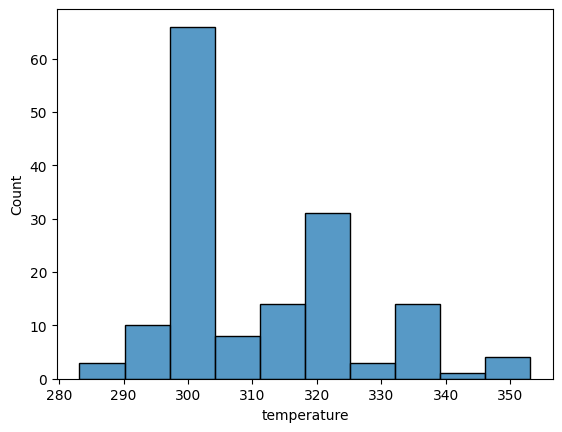

In [14]:
sns.histplot(data=iteration_analysis.to_pandas(), x="temperature")
plt.show()